In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "raw" / "application_train.csv"

con = duckdb.connect()

con.execute(f"""
    CREATE OR REPLACE VIEW applications AS
    SELECT *
    FROM read_csv_auto('{DATA_PATH.as_posix()}')
""")

In [2]:
query = """
WITH borrower_ratios AS (
    SELECT
        SK_ID_CURR,
        TARGET,
        AMT_CREDIT / NULLIF(AMT_INCOME_TOTAL, 0)
            AS credit_income_ratio
    FROM applications
    WHERE AMT_INCOME_TOTAL > 0
),
segmented AS (
    SELECT
        *,
        NTILE(5) OVER (
            ORDER BY credit_income_ratio
        ) AS risk_quintile
    FROM borrower_ratios
)
SELECT
    risk_quintile,
    COUNT(*) AS applicants,
    ROUND(AVG(credit_income_ratio), 2)
        AS avg_credit_income_ratio,
    ROUND(100.0 * AVG(TARGET), 2)
        AS difficulty_rate_pct
FROM segmented
GROUP BY risk_quintile
ORDER BY risk_quintile;
"""
display(con.execute(query).df())

,risk_quintile,applicants,avg_credit_income_ratio,difficulty_rate_pct
0,1,61503,1.27,7.33
1,2,61502,2.28,8.57
2,3,61502,3.28,8.93
3,4,61502,4.75,8.28
4,5,61502,8.21,7.25


In [3]:
query = """
WITH income_groups AS (
    SELECT
        TARGET,
        AMT_CREDIT,
        AMT_INCOME_TOTAL,
        NTILE(5) OVER (
            ORDER BY AMT_INCOME_TOTAL
        ) AS income_quintile
    FROM applications
    WHERE AMT_INCOME_TOTAL > 0
)
SELECT
    income_quintile,
    COUNT(*) AS applicants,
    ROUND(AVG(AMT_INCOME_TOTAL), 2)
        AS avg_income,
    ROUND(AVG(AMT_CREDIT), 2)
        AS avg_credit,
    ROUND(100.0 * AVG(TARGET), 2)
        AS difficulty_rate_pct
FROM income_groups
GROUP BY income_quintile
ORDER BY income_quintile;
"""
display(con.execute(query).df())

,income_quintile,applicants,avg_income,avg_credit,difficulty_rate_pct
0,1,61503,77327.01,384695.09,8.18
1,2,61502,117028.74,496708.73,8.72
2,3,61502,146600.17,579600.96,8.53
3,4,61502,192247.50,683154.00,8.12
4,5,61502,310787.68,850974.71,6.80


In [4]:
query = """
WITH payment_ratios AS (
    SELECT
        TARGET,
        AMT_ANNUITY / NULLIF(AMT_INCOME_TOTAL, 0)
            AS annuity_income_ratio
    FROM applications
    WHERE AMT_INCOME_TOTAL > 0
      AND AMT_ANNUITY IS NOT NULL
),
segmented AS (
    SELECT
        *,
        NTILE(5) OVER (
            ORDER BY annuity_income_ratio
        ) AS payment_quintile
    FROM payment_ratios
)
SELECT
    payment_quintile,
    COUNT(*) AS applicants,
    ROUND(AVG(annuity_income_ratio), 3)
        AS avg_annuity_income_ratio,
    ROUND(100.0 * AVG(TARGET), 2)
        AS difficulty_rate_pct
FROM segmented
GROUP BY payment_quintile
ORDER BY payment_quintile;
"""
display(con.execute(query).df())

,payment_quintile,applicants,avg_annuity_income_ratio,difficulty_rate_pct
0,1,61500,0.076,7.20
1,2,61500,0.124,7.83
2,3,61500,0.163,8.13
3,4,61500,0.214,8.70
4,5,61499,0.327,8.51


In [7]:
query = """
WITH employment_groups AS (
    SELECT
        TARGET,
        CASE
            WHEN DAYS_EMPLOYED = 365243 THEN 'Sentinel value'
            WHEN DAYS_EMPLOYED IS NULL THEN 'Missing'
            WHEN DAYS_EMPLOYED > 0 THEN 'Other positive'
            WHEN -DAYS_EMPLOYED / 365.25 < 1 THEN '<1 year'
            WHEN -DAYS_EMPLOYED / 365.25 < 3 THEN '1-3 years'
            WHEN -DAYS_EMPLOYED / 365.25 < 5 THEN '3-5 years'
            WHEN -DAYS_EMPLOYED / 365.25 < 10 THEN '5-10 years'
            ELSE '10+ years'
        END AS employment_group
    FROM applications
)
SELECT
    employment_group,
    COUNT(*) AS applicants,
    ROUND(100.0 * AVG(TARGET), 2)
        AS difficulty_rate_pct
FROM employment_groups
GROUP BY employment_group
ORDER BY
    CASE employment_group
        WHEN '<1 year' THEN 1
        WHEN '1-3 years' THEN 2
        WHEN '3-5 years' THEN 3
        WHEN '5-10 years' THEN 4
        WHEN '10+ years' THEN 5
        ELSE 8
    END;
"""
display(con.execute(query).df())

,employment_group,applicants,difficulty_rate_pct
0,<1 year,27982,10.97
1,1-3 years,61472,11.07
2,3-5 years,46902,9.67
3,5-10 years,64871,7.37
4,10+ years,50910,5.19
5,Sentinel value,55374,5.40


In [9]:
sql_file = ROOT / "sql" / "02_borrower_risk_analysis.sql"

queries = [
    q.strip()
    for q in sql_file.read_text().split(";")
    if q.strip()
]

results = []

for i, query in enumerate(queries, start=1):
    result = con.execute(query).df()
    results.append(result)

    print(f"Query {i}")
    display(result)

Query 1


,risk_quintile,applicants,avg_credit_income_ratio,difficulty_rate_pct
0,1,61503,1.27,7.34
1,2,61502,2.28,8.57
2,3,61502,3.28,8.92
3,4,61502,4.75,8.28
4,5,61502,8.21,7.25


Query 2


,income_quintile,applicants,avg_income,avg_credit,difficulty_rate_pct
0,1,61503,77327.01,384795.96,8.18
1,2,61502,117028.74,496510.93,8.72
2,3,61502,146600.17,579731.07,8.53
3,4,61502,192247.50,683443.04,8.14
4,5,61502,310787.68,850652.48,6.79


Query 3


,payment_quintile,applicants,avg_annuity_income_ratio,difficulty_rate_pct
0,1,61500,0.076,7.20
1,2,61500,0.124,7.83
2,3,61500,0.163,8.13
3,4,61500,0.214,8.70
4,5,61499,0.327,8.51


Query 4


,employment_group,applicants,difficulty_rate_pct
0,<1 year,27982,10.97
1,1-3 years,61472,11.07
2,3-5 years,46902,9.67
3,5-10 years,64871,7.37
4,10+ years,50910,5.19
5,Sentinel value,55374,5.40


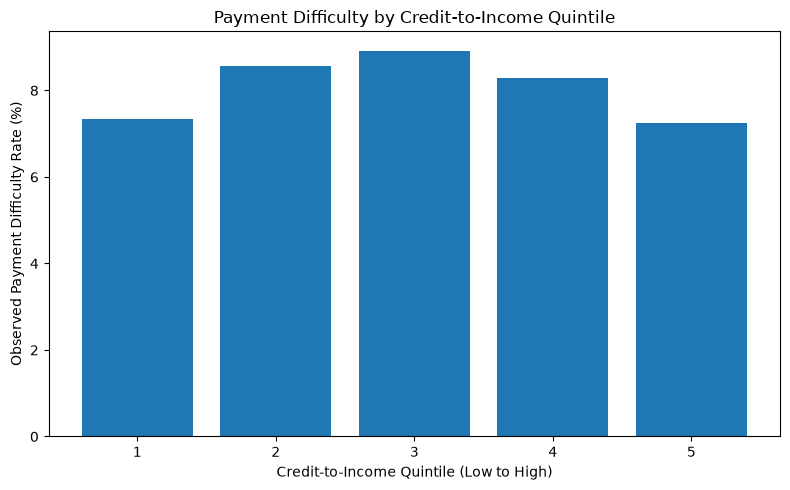

In [10]:
risk_df = results[0]

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    risk_df["risk_quintile"].astype(str),
    risk_df["difficulty_rate_pct"]
)

ax.set_title("Payment Difficulty by Credit-to-Income Quintile")
ax.set_xlabel("Credit-to-Income Quintile (Low to High)")
ax.set_ylabel("Observed Payment Difficulty Rate (%)")

plt.tight_layout()
plt.show()

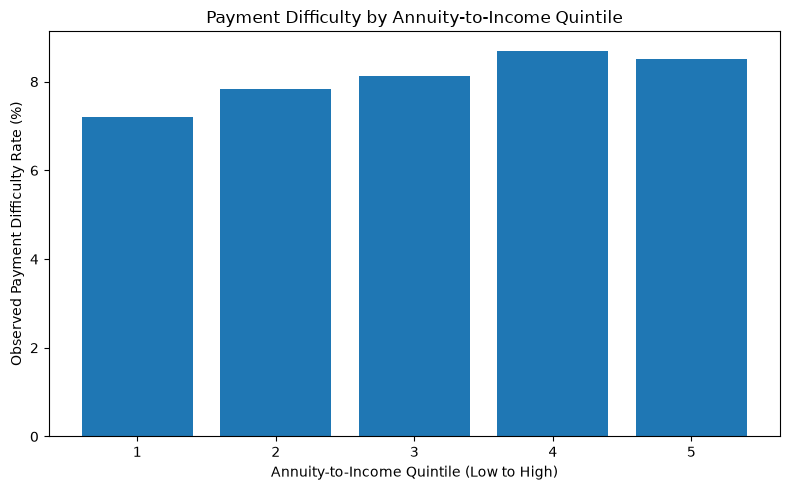

In [13]:
risk_df = results[2]

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    risk_df["payment_quintile"].astype(str),
    risk_df["difficulty_rate_pct"]
)

ax.set_title("Payment Difficulty by Annuity-to-Income Quintile")
ax.set_xlabel("Annuity-to-Income Quintile (Low to High)")
ax.set_ylabel("Observed Payment Difficulty Rate (%)")

plt.tight_layout()
plt.show()